In [21]:
# Cell 1: Install and import libraries

!pip -q install pandas numpy scikit-learn statsmodels matplotlib seaborn

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
import json
import os
import warnings

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.metrics import (
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)
from IPython.display import display

warnings.filterwarnings("ignore")

SEED = 652

print("Libraries imported successfully.")
print("Random seed:", SEED)

Libraries imported successfully.
Random seed: 652


In [22]:
# Cell 2: Load dataset

DATA_URL = (
    "https://raw.githubusercontent.com/propublica/"
    "compas-analysis/master/compas-scores-two-years.csv"
)

try:
    df_raw = pd.read_csv(DATA_URL)
except Exception as e:
    print("Automatic download failed.")
    from google.colab import files
    uploaded = files.upload()
    filename = next(iter(uploaded.keys()))
    df_raw = pd.read_csv(filename)

print("Dataset loaded successfully.")
print("Rows:", df_raw.shape[0])
print("Columns:", df_raw.shape[1])

display(df_raw.head())

Dataset loaded successfully.
Rows: 7214
Columns: 53


,id,name,first,last,compas_screening_date,sex,dob,age,age_cat,race,...,v_decile_score,v_score_text,v_screening_date,in_custody,out_custody,priors_count.1,start,end,event,two_year_recid
0,1,miguel hernandez,miguel,hernandez,2013-08-14,Male,1947-04-18,69,Greater than 45,Other,...,1,Low,2013-08-14,2014-07-07,2014-07-14,0,0,327,0,0
1,3,kevon dixon,kevon,dixon,2013-01-27,Male,1982-01-22,34,25 - 45,African-American,...,1,Low,2013-01-27,2013-01-26,2013-02-05,0,9,159,1,1
2,4,ed philo,ed,philo,2013-04-14,Male,1991-05-14,24,Less than 25,African-American,...,3,Low,2013-04-14,2013-06-16,2013-06-16,4,0,63,0,1
3,5,marcu brown,marcu,brown,2013-01-13,Male,1993-01-21,23,Less than 25,African-American,...,6,Medium,2013-01-13,NaN,NaN,1,0,1174,0,0
4,6,bouthy pierrelouis,bouthy,pierrelouis,2013-03-26,Male,1973-01-22,43,25 - 45,Other,...,1,Low,2013-03-26,NaN,NaN,2,0,1102,0,0


In [23]:
# Cell 3: Audit and preprocess the dataset

print("Original dataset shape:", df_raw.shape)
print("Duplicate rows:", df_raw.duplicated().sum())

print("\nMissing values in the most affected columns:")
display(
    df_raw.isnull()
    .sum()
    .sort_values(ascending=False)
    .head(20)
    .to_frame("Missing values")
)

df = df_raw.copy()

# Apply COMPAS screening filters.
before = len(df)

df = df[
    df["days_b_screening_arrest"].between(-30, 30)
]
df = df[df["is_recid"] != -1]
df = df[df["c_charge_degree"] != "O"]
df = df[df["score_text"] != "N/A"].copy()

print("Rows before screening:", before)
print("Rows after screening:", len(df))
print("Rows removed:", before - len(df))

# Convert important numerical columns safely.
numeric_targets = [
    "decile_score",
    "is_recid",
    "age",
    "priors_count"
]

for col in numeric_targets:
    df[col] = pd.to_numeric(df[col], errors="coerce")

# The two target variables must be available.
df = df.dropna(
    subset=["decile_score", "is_recid"]
).copy()

df["is_recid"] = df["is_recid"].astype(int)

print("\nCleaned dataset shape:", df.shape)
print("\nRecidivism outcome distribution:")
display(df["is_recid"].value_counts().to_frame("Count"))

print("\nDescriptive statistics:")
display(
    df[
        ["age", "priors_count", "decile_score", "is_recid"]
    ].describe().round(3)
)

Original dataset shape: (7214, 53)
Duplicate rows: 0

Missing values in the most affected columns:


,Missing values
violent_recid,7214
vr_charge_degree,6395
vr_offense_date,6395
vr_case_number,6395
vr_charge_desc,6395
c_arrest_date,6077
r_jail_in,4898
r_days_from_arrest,4898
r_jail_out,4898
r_charge_desc,3801


Rows before screening: 7214
Rows after screening: 6172
Rows removed: 1042

Cleaned dataset shape: (6172, 53)

Recidivism outcome distribution:


,Count
is_recid,
0,3182
1,2990



Descriptive statistics:


,age,priors_count,decile_score,is_recid
count,6172.000,6172.000,6172.000,6172.000
mean,34.535,3.246,4.419,0.484
std,11.731,4.744,2.839,0.500
min,18.000,0.000,1.000,0.000
25%,25.000,0.000,2.000,0.000
50%,31.000,1.000,4.000,0.000
75%,42.000,4.000,7.000,1.000
max,96.000,38.000,10.000,1.000


In [24]:
# Cell 4: Choose features and make the train-test split

numeric_features = [
    col for col in [
        "age",
        "priors_count",
        "juv_fel_count",
        "juv_misd_count",
        "juv_other_count"
    ]
    if col in df.columns
]

categorical_features = [
    col for col in [
        "sex",
        "race",
        "age_cat",
        "c_charge_degree"
    ]
    if col in df.columns
]

feature_cols = numeric_features + categorical_features

X = df[feature_cols].copy()

# Targets required by the assignment
y_score = df["decile_score"].astype(float)
y_recid = df["is_recid"].astype(int)

# Split the row indices only once so both models use the same test rows.
train_idx, test_idx = train_test_split(
    df.index,
    test_size=0.30,
    random_state=SEED,
    stratify=y_recid
)

X_train = X.loc[train_idx]
X_test = X.loc[test_idx]

y_score_train = y_score.loc[train_idx]
y_score_test = y_score.loc[test_idx]

y_recid_train = y_recid.loc[train_idx]
y_recid_test = y_recid.loc[test_idx]

print("Numeric features:", numeric_features)
print("Categorical features:", categorical_features)
print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))
print("Training proportion:", round(len(X_train) / len(df), 3))
print("Testing proportion:", round(len(X_test) / len(df), 3))

Numeric features: ['age', 'priors_count', 'juv_fel_count', 'juv_misd_count', 'juv_other_count']
Categorical features: ['sex', 'race', 'age_cat', 'c_charge_degree']
Training rows: 4320
Testing rows: 1852
Training proportion: 0.7
Testing proportion: 0.3


In [25]:
# Cell 5: Define preprocessing

def make_preprocessor():
    numeric_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ])

    categorical_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="ignore"))
    ])

    return ColumnTransformer([
        ("numeric", numeric_pipeline, numeric_features),
        ("categorical", categorical_pipeline, categorical_features)
    ])

print("Preprocessing pipeline is ready.")

Preprocessing pipeline is ready.


In [26]:
# Cell 6: Fit Model A and Model B

# Model A: Linear Regression predicts decile_score.
model_a = Pipeline([
    ("preprocessing", make_preprocessor()),
    ("model", LinearRegression())
])

model_a.fit(X_train, y_score_train)
pred_score = model_a.predict(X_test)

# Model B: Logistic Regression predicts is_recid.
model_b = Pipeline([
    ("preprocessing", make_preprocessor()),
    ("model", LogisticRegression(
        max_iter=3000,
        random_state=SEED
    ))
])

model_b.fit(X_train, y_recid_train)
pred_prob = model_b.predict_proba(X_test)[:, 1]

# Assignment's thresholds
median_score = np.median(pred_score)
class_a = (pred_score >= median_score).astype(int)
class_b = (pred_prob >= 0.5).astype(int)

# Confusion matrix comparing the two classification approaches
cm = confusion_matrix(class_a, class_b, labels=[0, 1])

mismatches = class_a != class_b
mismatch_count = int(mismatches.sum())
mismatch_pct = 100 * mismatch_count / len(class_a)

print("Median predicted decile score:", round(median_score, 4))
print("Logistic probability threshold: 0.5000")
print("Test cases:", len(class_a))
print("Mismatches:", mismatch_count)
print("Mismatch percentage:", round(mismatch_pct, 2), "%")

display(
    pd.DataFrame(
        cm,
        index=["Linear: Low", "Linear: High"],
        columns=["Logistic: Low", "Logistic: High"]
    )
)

# Additional diagnostic performance against is_recid.
# Remember: Model A's intended target is decile_score, not is_recid.
results = pd.DataFrame([
    {
        "Model": "Linear Regression (median threshold)",
        "Accuracy_vs_is_recid": accuracy_score(y_recid_test, class_a),
        "Precision": precision_score(y_recid_test, class_a, zero_division=0),
        "Recall": recall_score(y_recid_test, class_a, zero_division=0),
        "F1": f1_score(y_recid_test, class_a, zero_division=0)
    },
    {
        "Model": "Logistic Regression (0.5 threshold)",
        "Accuracy_vs_is_recid": accuracy_score(y_recid_test, class_b),
        "Precision": precision_score(y_recid_test, class_b, zero_division=0),
        "Recall": recall_score(y_recid_test, class_b, zero_division=0),
        "F1": f1_score(y_recid_test, class_b, zero_division=0)
    }
])

display(results.round(4))

Median predicted decile score: 4.3688
Logistic probability threshold: 0.5000
Test cases: 1852
Mismatches: 196
Mismatch percentage: 10.58 %


,Logistic: Low,Logistic: High
Linear: Low,880,45
Linear: High,151,776


,Model,Accuracy_vs_is_recid,Precision,Recall,F1
0,Linear Regression (median threshold),0.6631,0.6472,0.6689,0.6579
1,Logistic Regression (0.5 threshold),0.6814,0.6870,0.6288,0.6566


In [27]:
# Cell 7: Subgroup logistic regression

def fit_logit(data, predictors):
    """
    Fit a statsmodels logistic regression.
    Returns the fitted model after dropping missing observations
    in the specified outcome/predictor columns.
    """
    needed = ["is_recid"] + predictors
    d = data[needed].dropna().copy()

    X_sm = d[predictors].astype(float)
    X_sm = sm.add_constant(X_sm, has_constant="add")

    y_sm = d["is_recid"].astype(int)

    fitted = sm.Logit(y_sm, X_sm).fit(
        disp=False,
        maxiter=300
    )
    return fitted

# Prepare subgroup analysis data
subgroup_data = df[
    ["is_recid", "priors_count", "age", "sex", "race"]
].copy()

subgroup_data["sex_male"] = (
    subgroup_data["sex"].astype(str).str.lower() == "male"
).astype(int)

subgroup_data = subgroup_data.dropna(
    subset=["is_recid", "priors_count", "age", "sex_male", "race"]
)

# Full model
full_subgroup_model = fit_logit(
    subgroup_data,
    ["priors_count", "age", "sex_male"]
)

# Select two major race groups available in the data
race_counts = subgroup_data["race"].value_counts()
race_groups = [
    r for r in ["African-American", "Caucasian"]
    if r in race_counts.index
]

if len(race_groups) < 2:
    race_groups = list(race_counts.head(2).index)

subgroup_models = {}

for race_name in race_groups:
    data_g = subgroup_data[
        subgroup_data["race"] == race_name
    ]
    subgroup_models[race_name] = fit_logit(
        data_g,
        ["priors_count", "age", "sex_male"]
    )

# Extract coefficient, 95% CI, p-value and sample size
def extract_coefficient(label, fitted_model, variable):
    ci = fitted_model.conf_int().loc[variable]

    return {
        "Model": label,
        "Predictor": variable,
        "Coefficient": fitted_model.params[variable],
        "CI_lower": ci.iloc[0],
        "CI_upper": ci.iloc[1],
        "p_value": fitted_model.pvalues[variable],
        "Sample_size": int(fitted_model.nobs)
    }

subgroup_results = [
    extract_coefficient(
        "Full dataset",
        full_subgroup_model,
        "priors_count"
    )
]

for race_name, fitted_model in subgroup_models.items():
    subgroup_results.append(
        extract_coefficient(
            race_name,
            fitted_model,
            "priors_count"
        )
    )

subgroup_table = pd.DataFrame(subgroup_results)

display(subgroup_table.round(4))

,Model,Predictor,Coefficient,CI_lower,CI_upper,p_value,Sample_size
0,Full dataset,priors_count,0.1815,0.1655,0.1975,0.0,6172
1,African-American,priors_count,0.1656,0.1456,0.1857,0.0,3175
2,Caucasian,priors_count,0.2049,0.1706,0.2391,0.0,2103


In [28]:
# Cell 8: Omitted-variable bias

ovb = df[
    [
        "is_recid",
        "age",
        "priors_count",
        "sex",
        "race",
        "c_charge_degree",
        "juv_fel_count",
        "juv_misd_count"
    ]
].copy()

# Create simple binary indicators
ovb["sex_male"] = (
    ovb["sex"].astype(str).str.lower() == "male"
).astype(int)

ovb["race_black"] = (
    ovb["race"].astype(str) == "African-American"
).astype(int)

ovb["charge_felony"] = (
    ovb["c_charge_degree"].astype(str) == "F"
).astype(int)

# Full and reduced models use the same complete-case sample.
full_predictors = [
    "age",
    "priors_count",
    "sex_male",
    "race_black",
    "charge_felony",
    "juv_fel_count",
    "juv_misd_count"
]

ovb_clean = ovb[
    ["is_recid"] + full_predictors
].dropna().copy()

full_ovb_model = fit_logit(
    ovb_clean,
    full_predictors
)

# Deliberately drop priors_count
reduced_predictors = [
    p for p in full_predictors
    if p != "priors_count"
]

reduced_ovb_model = fit_logit(
    ovb_clean,
    reduced_predictors
)

# Compare coefficients in the two models
ovb_rows = []

for variable in reduced_predictors:
    full_coef = full_ovb_model.params[variable]
    reduced_coef = reduced_ovb_model.params[variable]

    absolute_change = abs(reduced_coef - full_coef)

    if abs(full_coef) > 1e-10:
        percent_change = (
            absolute_change / abs(full_coef)
        ) * 100
    else:
        percent_change = np.nan

    ovb_rows.append({
        "Predictor": variable,
        "Full_coefficient": full_coef,
        "Reduced_coefficient": reduced_coef,
        "Absolute_change": absolute_change,
        "Percent_change": percent_change
    })

ovb_table = pd.DataFrame(ovb_rows)
ovb_table = ovb_table.sort_values(
    "Percent_change",
    ascending=False
)

display(ovb_table.round(4))

print("Deliberately omitted variable: priors_count")

if len(ovb_table):
    largest = ovb_table.loc[
        ovb_table["Absolute_change"].idxmax()
    ]
    print("Largest absolute coefficient shift:", largest["Predictor"])
    print("Absolute shift:", round(largest["Absolute_change"], 4))

,Predictor,Full_coefficient,Reduced_coefficient,Absolute_change,Percent_change
5,juv_misd_count,0.0577,0.4701,0.4123,713.9567
4,juv_fel_count,0.1223,0.4988,0.3765,307.8612
2,race_black,0.1566,0.4146,0.2580,164.7723
3,charge_felony,0.1830,0.3502,0.1673,91.4033
0,age,-0.0446,-0.0285,0.0161,36.2023
1,sex_male,0.3874,0.5073,0.1199,30.9431


Deliberately omitted variable: priors_count
Largest absolute coefficient shift: juv_misd_count
Absolute shift: 0.4123


In [29]:
# Cell 9: Adversarial subset construction

adversarial = pd.DataFrame(
    {
        "actual": y_recid_test,
        "predicted_probability": pred_prob
    },
    index=X_test.index
)

# Confident but incorrect predictions
false_positive = (
    (adversarial["predicted_probability"] >= 0.75) &
    (adversarial["actual"] == 0)
)

false_negative = (
    (adversarial["predicted_probability"] <= 0.25) &
    (adversarial["actual"] == 1)
)

adversarial["error_type"] = np.select(
    [false_positive, false_negative],
    ["Confident false positive", "Confident false negative"],
    default=""
)

adversarial = adversarial[
    adversarial["error_type"] != ""
].copy()

total_confident_errors = len(adversarial)
error_pct = 100 * total_confident_errors / len(X_test)

print("Confident wrong predictions:", total_confident_errors)
print("Percentage of test set:", round(error_pct, 2), "%")

# Select at most 50 rows reproducibly
if total_confident_errors > 50:
    adversarial_sample = adversarial.sample(
        n=50,
        random_state=SEED
    )
else:
    adversarial_sample = adversarial.copy()

print("Rows selected for subset analysis:", len(adversarial_sample))
display(adversarial_sample.head(10))

Confident wrong predictions: 80
Percentage of test set: 4.32 %
Rows selected for subset analysis: 50


,actual,predicted_probability,error_type
7010,0,0.840499,Confident false positive
1716,0,0.848851,Confident false positive
1389,1,0.243019,Confident false negative
5954,1,0.207803,Confident false negative
6940,0,0.896758,Confident false positive
6854,1,0.230042,Confident false negative
820,0,0.931492,Confident false positive
1671,0,0.984304,Confident false positive
2032,1,0.198115,Confident false negative
482,1,0.213488,Confident false negative


In [30]:
# Cell 9B: Compare the demographics of the adversarial subset

demographic_cols = [
    col for col in ["age", "sex", "race", "priors_count"]
    if col in df.columns
]

test_demo = df.loc[X_test.index, demographic_cols].copy()
adv_demo = df.loc[adversarial_sample.index, demographic_cols].copy()

if "age" in demographic_cols:
    print("Age in full test set:")
    display(test_demo["age"].describe().to_frame().T.round(2))

    print("Age in adversarial subset:")
    display(adv_demo["age"].describe().to_frame().T.round(2))

for col in ["sex", "race"]:
    if col in demographic_cols:
        print(f"\n{col}: full test set (%)")
        display(
            (test_demo[col].value_counts(normalize=True) * 100)
            .round(2)
            .to_frame("Percentage")
        )

        print(f"{col}: adversarial subset (%)")
        display(
            (adv_demo[col].value_counts(normalize=True) * 100)
            .round(2)
            .to_frame("Percentage")
        )

if "priors_count" in demographic_cols:
    print("\nPrior count in the adversarial subset:")
    display(adv_demo["priors_count"].describe().to_frame().T.round(2))

# Investigate common categorical characteristics
for col in ["race", "sex", "age_cat", "c_charge_degree"]:
    if col in df.columns and len(adversarial_sample) > 0:
        print(f"\n{col}: adversarial subset (%)")
        display(
            (
                df.loc[adversarial_sample.index, col]
                .value_counts(normalize=True) * 100
            )
            .round(2)
            .to_frame("Percentage")
        )

Age in full test set:


,count,mean,std,min,25%,50%,75%,max
age,1852.0,34.27,11.49,19.0,25.0,31.0,42.0,96.0


Age in adversarial subset:


,count,mean,std,min,25%,50%,75%,max
age,50.0,45.8,14.46,22.0,34.5,47.5,55.0,96.0



sex: full test set (%)


...

,Percentage
sex,
Male,84.0
Female,16.0



age_cat: adversarial subset (%)


,Percentage
age_cat,
Greater than 45,54.0
25 - 45,40.0
Less than 25,6.0



c_charge_degree: adversarial subset (%)


,Percentage
c_charge_degree,
F,62.0
M,38.0


In [31]:
# Cell 10: Compute fairness metrics across thresholds

fair_data = pd.DataFrame(
    {
        "actual": y_recid_test,
        "probability": pred_prob
    },
    index=X_test.index
)

fair_data["race"] = df.loc[fair_data.index, "race"]

available_groups = fair_data["race"].value_counts().index.tolist()

if "African-American" in available_groups and "Caucasian" in available_groups:
    group_a = "African-American"
    group_b = "Caucasian"
else:
    group_a, group_b = available_groups[:2]

print("Group A:", group_a)
print("Group B:", group_b)

def safe_ratio(numerator, denominator):
    if pd.isna(numerator) or pd.isna(denominator):
        return np.nan
    if abs(denominator) < 1e-12:
        return np.nan
    return numerator / denominator

def group_rates(data, group_name, threshold):
    g = data[data["race"] == group_name]
    pred = g["probability"] >= threshold
    actual = g["actual"] == 1

    # Demographic parity: proportion classified positive
    selection_rate = pred.mean() if len(g) else np.nan

    # True positive rate
    tpr = (
        ((pred) & actual).sum() / actual.sum()
        if actual.sum() > 0 else np.nan
    )

    # False positive rate
    actual_negative = ~actual
    fpr = (
        ((pred) & actual_negative).sum() / actual_negative.sum()
        if actual_negative.sum() > 0 else np.nan
    )

    # Predictive parity: proportion truly positive among predicted positives
    ppv = (
        ((pred) & actual).sum() / pred.sum()
        if pred.sum() > 0 else np.nan
    )

    return {
        "selection_rate": selection_rate,
        "TPR": tpr,
        "FPR": fpr,
        "PPV": ppv
    }

thresholds = np.round(np.arange(0.05, 0.951, 0.10), 2)

fairness_rows = []

for threshold in thresholds:
    rates_a = group_rates(fair_data, group_a, threshold)
    rates_b = group_rates(fair_data, group_b, threshold)

    dp = safe_ratio(
        rates_a["selection_rate"],
        rates_b["selection_rate"]
    )

    tpr_ratio = safe_ratio(rates_a["TPR"], rates_b["TPR"])
    fpr_ratio = safe_ratio(rates_a["FPR"], rates_b["FPR"])

    valid_eo_ratios = [
        r for r in [tpr_ratio, fpr_ratio]
        if not pd.isna(r)
    ]

    eo = min(valid_eo_ratios) if valid_eo_ratios else np.nan

    pp = safe_ratio(rates_a["PPV"], rates_b["PPV"])

    fairness_rows.append({
        "Threshold": threshold,
        "DP_ratio": dp,
        "EO_ratio": eo,
        "PP_ratio": pp,
        f"Selection_{group_a}": rates_a["selection_rate"],
        f"Selection_{group_b}": rates_b["selection_rate"],
        f"TPR_{group_a}": rates_a["TPR"],
        f"TPR_{group_b}": rates_b["TPR"],
        f"FPR_{group_a}": rates_a["FPR"],
        f"FPR_{group_b}": rates_b["FPR"],
        f"PPV_{group_a}": rates_a["PPV"],
        f"PPV_{group_b}": rates_b["PPV"]
    })

fairness_table = pd.DataFrame(fairness_rows)

display(fairness_table.round(4))

Group A: African-American
Group B: Caucasian


,Threshold,DP_ratio,EO_ratio,PP_ratio,Selection_African-American,Selection_Caucasian,TPR_African-American,TPR_Caucasian,FPR_African-American,FPR_Caucasian,PPV_African-American,PPV_Caucasian
0,0.05,1.0000,1.0000,1.2630,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,0.5547,0.4392
1,0.15,1.0323,1.0105,1.2363,0.9946,0.9635,1.0000,0.9896,0.9880,0.9431,0.5577,0.4511
2,0.25,1.1998,1.0944,1.1521,0.9646,0.8040,0.9884,0.9031,0.9349,0.7263,0.5684,0.4934
3,0.35,1.4505,1.2141,1.0571,0.8487,0.5851,0.9284,0.7647,0.7494,0.4444,0.6068,0.5740
4,0.45,1.7609,1.4849,1.0650,0.6931,0.3936,0.8375,0.5640,0.5133,0.2602,0.6703,0.6293
5,0.55,2.3762,1.8209,0.9678,0.4839,0.2036,0.6364,0.3495,0.2940,0.0894,0.7295,0.7537
6,0.65,2.8448,1.9751,0.8769,0.2940,0.1033,0.4101,0.2076,0.1494,0.0217,0.7737,0.8824
7,0.75,3.9439,2.8810,0.9226,0.1738,0.0441,0.2592,0.0900,0.0675,0.0081,0.8272,0.8966
8,0.85,5.1988,4.0372,0.9808,0.0869,0.0167,0.1257,0.0311,0.0386,0.0054,0.8025,0.8182
9,0.95,4.7067,3.1676,0.8500,0.0215,0.0046,0.0329,0.0104,0.0072,0.0000,0.8500,1.0000


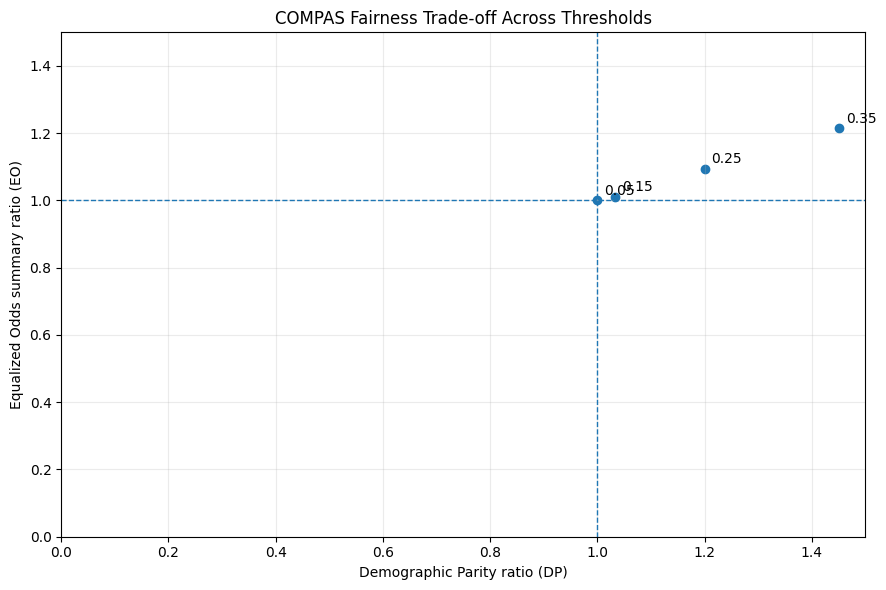

In [32]:
# Cell 11: Required DP versus EO trade-off chart

plot_data = fairness_table.dropna(
    subset=["DP_ratio", "EO_ratio"]
)

plt.figure(figsize=(9, 6))

plt.scatter(
    plot_data["DP_ratio"],
    plot_data["EO_ratio"]
)

for _, row in plot_data.iterrows():
    plt.annotate(
        f'{row["Threshold"]:.2f}',
        (row["DP_ratio"], row["EO_ratio"]),
        xytext=(5, 4),
        textcoords="offset points"
    )

plt.axvline(1.0, linestyle="--", linewidth=1)
plt.axhline(1.0, linestyle="--", linewidth=1)

plt.xlim(0, 1.5)
plt.ylim(0, 1.5)

plt.xlabel("Demographic Parity ratio (DP)")
plt.ylabel("Equalized Odds summary ratio (EO)")
plt.title("COMPAS Fairness Trade-off Across Thresholds")

plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

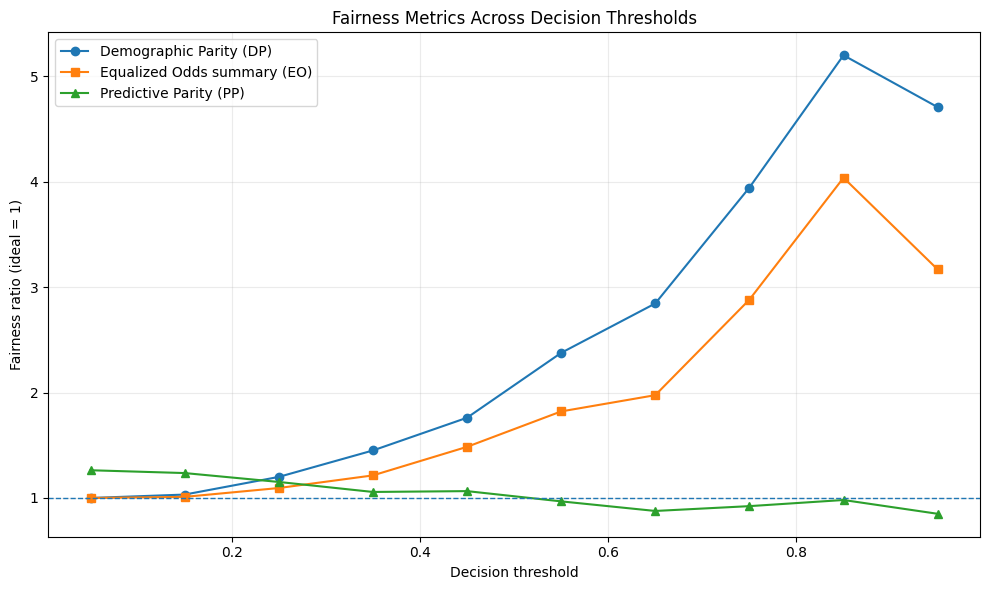

In [33]:
# Cell 11B: DP, EO and PP across thresholds

plt.figure(figsize=(10, 6))

plt.plot(
    fairness_table["Threshold"],
    fairness_table["DP_ratio"],
    marker="o",
    label="Demographic Parity (DP)"
)

plt.plot(
    fairness_table["Threshold"],
    fairness_table["EO_ratio"],
    marker="s",
    label="Equalized Odds summary (EO)"
)

plt.plot(
    fairness_table["Threshold"],
    fairness_table["PP_ratio"],
    marker="^",
    label="Predictive Parity (PP)"
)

plt.axhline(1.0, linestyle="--", linewidth=1)

plt.xlabel("Decision threshold")
plt.ylabel("Fairness ratio (ideal = 1)")
plt.title("Fairness Metrics Across Decision Thresholds")

plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

In [34]:
# FIX: Recreate missing Part 1 variables

from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.metrics import (
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

SEED = 652

# Model A: predict decile_score
model_a = Pipeline([
    ("preprocessing", make_preprocessor()),
    ("model", LinearRegression())
])

model_a.fit(X_train, y_score_train)
pred_score = model_a.predict(X_test)

# Model B: predict is_recid
model_b = Pipeline([
    ("preprocessing", make_preprocessor()),
    ("model", LogisticRegression(max_iter=3000, random_state=SEED))
])

model_b.fit(X_train, y_recid_train)
pred_prob = model_b.predict_proba(X_test)[:, 1]

# Apply the assignment's thresholds
median_score = float(np.median(pred_score))
class_a = (pred_score >= median_score).astype(int)
class_b = (pred_prob >= 0.5).astype(int)

# Agreement confusion matrix
cm = confusion_matrix(class_a, class_b, labels=[0, 1])
cm_agreement = cm

# Mismatch count and percentage
mismatch_count = int(np.sum(class_a != class_b))
mismatch_pct = 100 * mismatch_count / len(class_a)

# Recreate the results table required by Cell 12
results = pd.DataFrame([
    {
        "Model": "Linear Regression (median threshold)",
        "Accuracy_vs_is_recid": accuracy_score(y_recid_test, class_a),
        "Precision": precision_score(y_recid_test, class_a, zero_division=0),
        "Recall": recall_score(y_recid_test, class_a, zero_division=0),
        "F1": f1_score(y_recid_test, class_a, zero_division=0)
    },
    {
        "Model": "Logistic Regression (0.5 threshold)",
        "Accuracy_vs_is_recid": accuracy_score(y_recid_test, class_b),
        "Precision": precision_score(y_recid_test, class_b, zero_division=0),
        "Recall": recall_score(y_recid_test, class_b, zero_division=0),
        "F1": f1_score(y_recid_test, class_b, zero_division=0)
    }
])

metrics = results
median_pred_a = median_score
n_mismatch = mismatch_count
pct_mismatch = mismatch_pct

print("Part 1 results recreated successfully.")
print("Median predicted score:", round(median_score, 4))
print("Mismatches:", mismatch_count)
print("Mismatch percentage:", round(mismatch_pct, 2), "%")

display(results.round(4))
display(pd.DataFrame(
    cm,
    index=["Linear Low", "Linear High"],
    columns=["Logistic Low", "Logistic High"]
))

Part 1 results recreated successfully.
Median predicted score: 4.3688
Mismatches: 196
Mismatch percentage: 10.58 %


,Model,Accuracy_vs_is_recid,Precision,Recall,F1
0,Linear Regression (median threshold),0.6631,0.6472,0.6689,0.6579
1,Logistic Regression (0.5 threshold),0.6814,0.6870,0.6288,0.6566


,Logistic Low,Logistic High
Linear Low,880,45
Linear High,151,776


## Final export — save tables and summary
Run this after all analysis cells, including the Part 1 fix cell, complete successfully.

In [ ]:
# FINAL EXPORT CELL: save computed assignment results
import os
import json
import pandas as pd

os.makedirs("compas_assignment_outputs", exist_ok=True)

# Part 1
results.to_csv("compas_assignment_outputs/part1_model_metrics.csv", index=False)
pd.DataFrame(
    cm,
    index=["Linear_Low", "Linear_High"],
    columns=["Logistic_Low", "Logistic_High"]
).to_csv("compas_assignment_outputs/part1_confusion_matrix.csv")

# Part 2.1–2.4
subgroup_table.to_csv("compas_assignment_outputs/part2_1_subgroups.csv", index=False)
ovb_table.to_csv("compas_assignment_outputs/part2_2_omitted_variable_bias.csv", index=False)
adversarial_sample.to_csv("compas_assignment_outputs/part2_3_adversarial_subset.csv", index=True)
fairness_table.to_csv("compas_assignment_outputs/part2_4_fairness_metrics.csv", index=False)

summary = {
    "random_seed": int(SEED),
    "raw_rows": int(len(df_raw)),
    "analysis_rows_after_screening": int(len(df)),
    "training_rows": int(len(X_train)),
    "test_rows": int(len(X_test)),
    "median_predicted_decile_score": float(median_score),
    "mismatch_count": int(mismatch_count),
    "mismatch_percentage": float(mismatch_pct),
    "confident_wrong_predictions_in_full_test_set": int(total_confident_errors),
    "confident_wrong_percentage_of_test_set": float(error_pct),
    "race_group_a": str(group_a),
    "race_group_b": str(group_b)
}
with open("compas_assignment_outputs/summary.json", "w", encoding="utf-8") as f:
    json.dump(summary, f, indent=2)

print("Export completed. Files created:")
for filename in sorted(os.listdir("compas_assignment_outputs")):
    print(" -", filename)
print("\nSummary:")
print(json.dumps(summary, indent=2))


## Optional — create and download results ZIP

In [ ]:
# OPTIONAL: create and download the ZIP file (Google Colab)
import os
import shutil

zip_path = shutil.make_archive(
    "/content/compas_assignment_outputs",
    "zip",
    root_dir="/content",
    base_dir="compas_assignment_outputs"
)
print("ZIP created at:", zip_path)

try:
    from google.colab import files
    files.download(zip_path)
except ImportError:
    print("Not running in Google Colab. Download the ZIP from the file browser:", zip_path)
